# Seminar 5 – Predicting student grade with an ensemble of tree models
A decision tree, a random forest and three gradient-boosted tree libraries (CatBoost, XGBoost, LightGBM) are tuned separately, then combined by a **plain average of their predicted class probabilities**.

Scores (no single score decides the winner):
- **Macro F1** – classification quality, every grade weighted equally (higher is better)
- **MAE** – average distance in grade steps on the ordinal scale `Fail=0 … AA=7` (lower is better)
- **RMSLE** – root mean squared log error on the same scale (lower is better); because of the log, mistakes near the bottom of the scale (e.g. predicting `CC` for a `Fail`) cost more than the same-sized mistake near the top

In [24]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.base import BaseEstimator, ClassifierMixin
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import f1_score, mean_absolute_error, mean_squared_log_error, confusion_matrix, make_scorer
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
SEED = 42

GRADE_ORDER = ["Fail", "DD", "DC", "CC", "CB", "BB", "BA", "AA"]
raw = pd.read_csv("data/students_two.csv")
raw.shape

(145, 14)

## 1. Data cleaning

In [25]:
df = raw.copy()

# Strip whitespace from all text columns
obj_cols = df.select_dtypes("object").columns
df[obj_cols] = df[obj_cols].apply(lambda s: s.str.strip())

# Invalid entries found in the EDA -> missing (imputed later inside the CV pipeline)
VALID = {
    "Attendance": ["Always", "Sometimes", "Never"],
    "Notes": ["Yes", "No"],
    "Listening_in_Class": ["Yes", "No"],
}
for col, allowed in VALID.items():
    bad = ~df[col].isin(allowed) & df[col].notna()
    print(f"{col}: {bad.sum()} invalid -> NaN {df.loc[bad, col].unique().tolist()}")
    df.loc[bad, col] = np.nan

print("Duplicate rows:", df.duplicated(subset=df.columns.drop("Id")).sum())
df.isna().sum()[lambda s: s > 0]

Attendance: 1 invalid -> NaN ['3']
Notes: 2 invalid -> NaN ['6']
Listening_in_Class: 1 invalid -> NaN ['6']
Duplicate rows: 0


/var/folders/6f/lwymzlcj4m71df5w5zt98s8w0000gn/T/ipykernel_10994/3442577982.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj_cols = df.select_dtypes("object").columns


Scholarship           1
Attendance            1
Notes                 2
Listening_in_Class    1
dtype: int64

### Leakage check on `Id`
`Id` is a row label, not a student attribute. If the file was sorted by grade, `Id` would leak the target, so it is checked and then dropped.

In [26]:
grade_code = df["Grade"].map(GRADE_ORDER.index)
print("Spearman corr(Id, grade):", round(df["Id"].corr(grade_code, method="spearman"), 3))
df = df.drop(columns="Id")

Spearman corr(Id, grade): -0.262


### Encoding
All mappings are fixed (not learned from the data), so they can be applied before the train/test split without leakage. Missing values stay as NaN and are imputed inside each CV fold.

In [27]:
YES_NO = ["Additional_Work", "Sports_activity", "Reading", "Notes", "Listening_in_Class", "Project_work"]

X = pd.DataFrame(index=df.index)
X["Student_Age"] = df["Student_Age"]
X["Weekly_Study_Hours"] = df["Weekly_Study_Hours"]
X["Scholarship_pct"] = df["Scholarship"].str.rstrip("%").astype(float)
X["Attendance"] = df["Attendance"].map({"Never": 0, "Sometimes": 1, "Always": 2})
X["Transport_Private"] = (df["Transportation"] == "Private").astype(int)
for c in YES_NO:
    X[c] = df[c].map({"Yes": 1, "No": 0})
X = X.join(pd.get_dummies(df["High_School_Type"], prefix="School", dtype=int))

# Derived features
X["Studies_at_all"] = (X["Weekly_Study_Hours"] > 0).astype(int)
X["Engagement"] = X[["Reading", "Notes", "Listening_in_Class", "Project_work"]].sum(axis=1, min_count=1)

y = df["Grade"].map(GRADE_ORDER.index).to_numpy()   # ordinal target 0..7
print(X.shape)
pd.Series(y).map(dict(enumerate(GRADE_ORDER))).value_counts().reindex(GRADE_ORDER)

(145, 16)


Fail     8
DD      17
DC      13
CC      17
CB      10
BB      21
BA      24
AA      35
Name: count, dtype: int64

In [28]:
X.head()

,Student_Age,Weekly_Study_Hours,Scholarship_pct,Attendance,Transport_Private,Additional_Work,Sports_activity,Reading,Notes,Listening_in_Class,Project_work,School_Other,School_Private,School_State,Studies_at_all,Engagement
0,21,0,50.0,2.0,1,1,0,1,1.0,0.0,0,1,0,0,0,2.0
1,20,0,50.0,2.0,1,1,0,1,0.0,1.0,1,1,0,0,0,3.0
2,21,2,50.0,0.0,1,0,0,0,0.0,0.0,1,0,0,1,1,1.0
3,18,2,50.0,2.0,0,1,0,0,1.0,0.0,0,0,1,0,1,1.0
4,22,12,50.0,2.0,0,0,0,1,0.0,1.0,1,0,1,0,1,3.0


## 2. Scores

In [29]:
def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro", zero_division=0)

def mae(y_true, y_pred):
    return mean_absolute_error(y_true, y_pred)

def rmsle(y_true, y_pred):
    return np.sqrt(mean_squared_log_error(y_true, y_pred))

SCORES = {"macro_F1": macro_f1, "MAE": mae, "RMSLE": rmsle}
HIGHER_IS_BETTER = {"macro_F1": True, "MAE": False, "RMSLE": False}

## 3. Models
Small data (145 rows, 8 grades, smallest grade has 8 rows) → shallow trees, large leaves and strong regularisation.
Class imbalance is handled with balanced class/sample weights so rare grades are not ignored.

Hyperparameters are tuned by an inner 3-fold CV (selected on macro F1) inside every outer fold, i.e. **nested CV**, so the reported scores are not optimistic.

In [30]:
def make_pipe(model):
    return Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("model", model)])

MODELS = {
    "Decision tree": (
        make_pipe(DecisionTreeClassifier(class_weight="balanced", random_state=SEED)),
        {"model__max_depth": [2, 3, 4, 6], "model__min_samples_leaf": [3, 5, 8]},
    ),
    "Random forest": (
        make_pipe(RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                         random_state=SEED, n_jobs=-1)),
        {"model__max_depth": [4, 8, None], "model__min_samples_leaf": [1, 3],
         "model__max_features": ["sqrt", 0.5]},
    ),
    # Gradient-boosted trees: one thread each, GridSearchCV parallelises across fits
    "CatBoost": (
        make_pipe(CatBoostClassifier(iterations=300, auto_class_weights="Balanced", random_seed=SEED,
                                     thread_count=1, verbose=0, allow_writing_files=False)),
        {"model__learning_rate": [0.03, 0.1], "model__depth": [3, 4],
         "model__l2_leaf_reg": [3, 10]},
    ),
    "XGBoost": (
        make_pipe(XGBClassifier(n_estimators=200, subsample=0.8, colsample_bytree=0.8,
                                random_state=SEED, n_jobs=1)),
        {"model__learning_rate": [0.05, 0.1], "model__max_depth": [2, 3],
         "model__reg_lambda": [1, 10]},
    ),
    "LightGBM": (
        make_pipe(LGBMClassifier(n_estimators=200, class_weight="balanced", subsample=0.8,
                                 subsample_freq=1, colsample_bytree=0.8,
                                 random_state=SEED, n_jobs=1, verbose=-1)),
        {"model__learning_rate": [0.05, 0.1], "model__num_leaves": [4, 8],
         "model__min_child_samples": [5, 10]},
    ),
}

INNER_CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
TUNE_SCORER = make_scorer(macro_f1)

def fit_tuned(name, X_tr, y_tr):
    pipe, grid = MODELS[name]
    gs = GridSearchCV(pipe, grid, scoring=TUNE_SCORER, cv=INNER_CV, n_jobs=-1)
    fit_params = {}
    if name == "XGBoost":   # no class_weight option -> balanced sample weights
        fit_params["model__sample_weight"] = compute_sample_weight("balanced", y_tr)
    return gs.fit(X_tr, y_tr, **fit_params)

## 4. Nested cross-validation and the plain-average ensemble
Outer loop: stratified 5-fold, repeated 3 times (15 test folds). In each fold the five models are tuned on the training part, and the **ensemble = mean of their `predict_proba`**, predicted grade = most probable grade.

In [32]:
OUTER_CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=1, random_state=SEED)
CLASSES = np.arange(len(GRADE_ORDER))

def full_proba(est, X_):
    # Align probability columns to all 8 grades (a training fold may miss a rare grade)
    p = np.zeros((len(X_), len(CLASSES)))
    p[:, est.classes_] = est.predict_proba(X_)
    return p

rows, oof, best_params = [], [], []
for fold, (tr, te) in enumerate(OUTER_CV.split(X, y)):
    X_tr, X_te, y_tr, y_te = X.iloc[tr], X.iloc[te], y[tr], y[te]
    preds, probas = {}, []

    dummy = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
    preds["Baseline (most frequent)"] = dummy.predict(X_te)

    for name in MODELS:
        gs = fit_tuned(name, X_tr, y_tr)
        p = full_proba(gs.best_estimator_, X_te)
        probas.append(p)
        preds[name] = CLASSES[p.argmax(axis=1)]
        best_params.append({"fold": fold, "model": name, **gs.best_params_})

    preds["Ensemble (plain average)"] = CLASSES[np.mean(probas, axis=0).argmax(axis=1)]

    for model, y_hat in preds.items():
        rows.append({"fold": fold, "model": model, **{s: f(y_te, y_hat) for s, f in SCORES.items()}})
        oof.append(pd.DataFrame({"fold": fold, "repeat": fold // 5, "model": model,
                                 "idx": te, "y_true": y_te, "y_pred": y_hat}))
    print(f"fold {fold + 1}/5 done")

results = pd.DataFrame(rows)
oof = pd.concat(oof, ignore_index=True)

fold 1/15 done
fold 2/15 done
fold 3/15 done
fold 4/15 done
fold 5/15 done


## 5. Results

In [33]:
MODEL_ORDER = ["Baseline (most frequent)", "Decision tree", "Random forest", "CatBoost", "XGBoost", "LightGBM",
               "Ensemble (plain average)"]
summary = results.groupby("model")[list(SCORES)].agg(["mean", "std"]).reindex(MODEL_ORDER)
summary.round(3)

macro_F1           MAE         RMSLE       
                             mean    std   mean    std   mean    std
model                                                               
Baseline (most frequent)    0.049  0.000  2.669  0.046  0.797  0.045
Decision tree               0.102  0.026  2.572  0.235  0.833  0.121
Random forest               0.172  0.043  2.145  0.194  0.759  0.053
CatBoost                    0.171  0.053  2.324  0.206  0.810  0.070
XGBoost                     0.152  0.045  2.269  0.209  0.798  0.087
LightGBM                    0.174  0.051  2.172  0.398  0.771  0.115
Ensemble (plain average)    0.168  0.037  2.248  0.193  0.806  0.062

In [34]:
# Rank of each model on each score (1 = best) and mean rank across the three scores
means = results.groupby("model")[list(SCORES)].mean().reindex(MODEL_ORDER)
ranks = pd.DataFrame({s: means[s].rank(ascending=not HIGHER_IS_BETTER[s]) for s in SCORES})
ranks["mean_rank"] = ranks.mean(axis=1)
ranks.sort_values("mean_rank")

,macro_F1,MAE,RMSLE,mean_rank
model,,,,
Random forest,2.0,1.0,1.0,1.333333
LightGBM,1.0,2.0,2.0,1.666667
Ensemble (plain average),4.0,3.0,5.0,4.000000
XGBoost,5.0,4.0,4.0,4.333333
CatBoost,3.0,5.0,6.0,4.666667
Baseline (most frequent),7.0,7.0,3.0,5.666667
Decision tree,6.0,6.0,7.0,6.333333


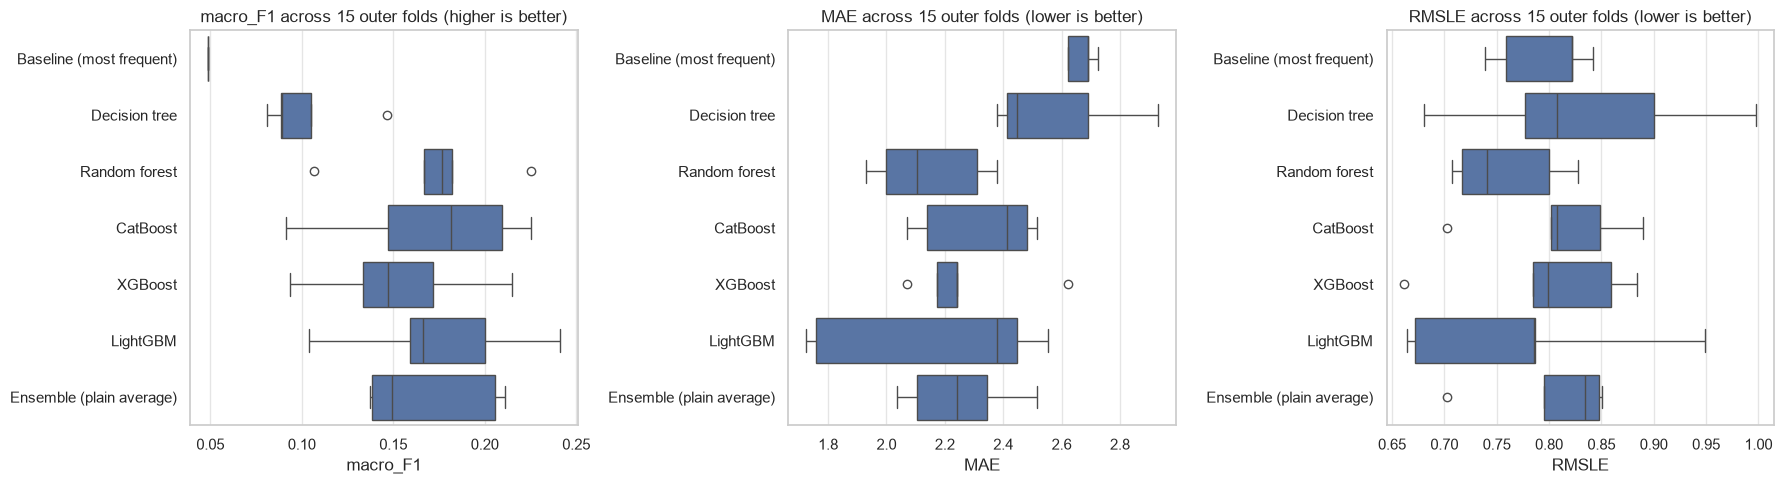

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, s in zip(axes, SCORES):
    sns.boxplot(data=results, y="model", x=s, order=MODEL_ORDER, ax=ax)
    ax.set_title(f"{s} across 15 outer folds ({'higher' if HIGHER_IS_BETTER[s] else 'lower'} is better)")
    ax.set_ylabel("")
plt.tight_layout(); plt.show()

In [36]:
# Most frequently chosen hyperparameters per model
bp = pd.DataFrame(best_params)
for name in MODELS:
    cols = [c for c in bp.columns if c.startswith("model__")]
    sub = bp[bp["model"] == name].dropna(axis=1, how="all")
    print(f"--- {name} ---")
    print(sub[[c for c in cols if c in sub]].astype(str).value_counts().head(3).to_string(), "\n")

--- Decision tree ---
model__max_depth  model__min_samples_leaf
6.0               3.0                        2
4.0               5.0                        1
6.0               5.0                        1 

--- Random forest ---
model__max_depth  model__min_samples_leaf  model__max_features
8.0               3.0                      sqrt                   2
4.0               1.0                      sqrt                   1
8.0               1.0                      0.5                    1 

--- CatBoost ---
model__depth  model__l2_leaf_reg  model__learning_rate
4.0           3.0                 0.1                     2
3.0           3.0                 0.1                     1
4.0           10.0                0.1                     1 

--- XGBoost ---
model__max_depth  model__learning_rate  model__reg_lambda
2.0               0.05                  1.0                  2
3.0               0.1                   10.0                 1
2.0               0.1                   10.0    

### Where does the ensemble make mistakes?
Confusion matrix from the out-of-fold predictions of the first repeat (every student predicted exactly once).

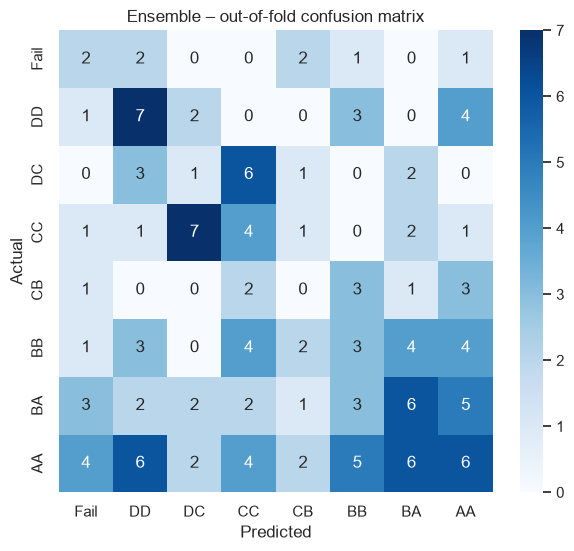

Exact grade: 20.0% | within 1 grade step: 52.4% | within 2: 64.1%


In [37]:
ens = oof[(oof["model"] == "Ensemble (plain average)") & (oof["repeat"] == 0)]
cm = confusion_matrix(ens["y_true"], ens["y_pred"], labels=CLASSES)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=GRADE_ORDER, yticklabels=GRADE_ORDER)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Ensemble – out-of-fold confusion matrix")
plt.show()

err = (ens["y_pred"] - ens["y_true"]).abs()
print("Exact grade:", f"{(err == 0).mean():.1%}", "| within 1 grade step:", f"{(err <= 1).mean():.1%}",
      "| within 2:", f"{(err <= 2).mean():.1%}")

## 6. Final model (trained on all data)
Each model is tuned once more on the full dataset, then averaged. This is the model to use on new students; its expected performance is the nested-CV estimate above, not a score on the training data.

In [38]:
final = {name: fit_tuned(name, X, y).best_estimator_ for name in MODELS}
for name, est in final.items():
    print(name, {k.replace("model__", ""): v for k, v in est.get_params().items()
                 if k in MODELS[name][1]})

def ensemble_predict_proba(X_new):
    return np.mean([full_proba(est, X_new) for est in final.values()], axis=0)

def ensemble_predict(X_new):
    return np.array(GRADE_ORDER)[ensemble_predict_proba(X_new).argmax(axis=1)]

Decision tree {'max_depth': 6, 'min_samples_leaf': 3}
Random forest {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 3}
CatBoost {'depth': 3, 'l2_leaf_reg': 3, 'learning_rate': 0.1}
XGBoost {'learning_rate': 0.05, 'max_depth': 2, 'reg_lambda': 10}
LightGBM {'learning_rate': 0.05, 'min_child_samples': 5, 'num_leaves': 4}


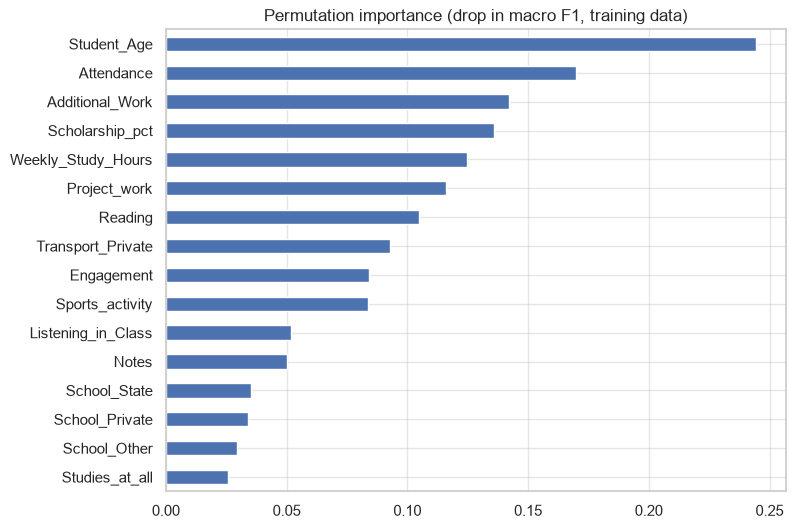

In [39]:
# Feature importance of the ensemble: permutation importance on macro F1
class AvgEnsemble(ClassifierMixin, BaseEstimator):
    def fit(self, X_, y_):   # base models are already fitted; only record the classes
        self.classes_ = CLASSES
        return self
    def predict(self, X_): return CLASSES[ensemble_predict_proba(X_).argmax(axis=1)]

pi = permutation_importance(AvgEnsemble().fit(X, y), X, y, scoring=make_scorer(macro_f1),
                            n_repeats=20, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()
imp.plot.barh(figsize=(8, 6), title="Permutation importance (drop in macro F1, training data)")
plt.show()

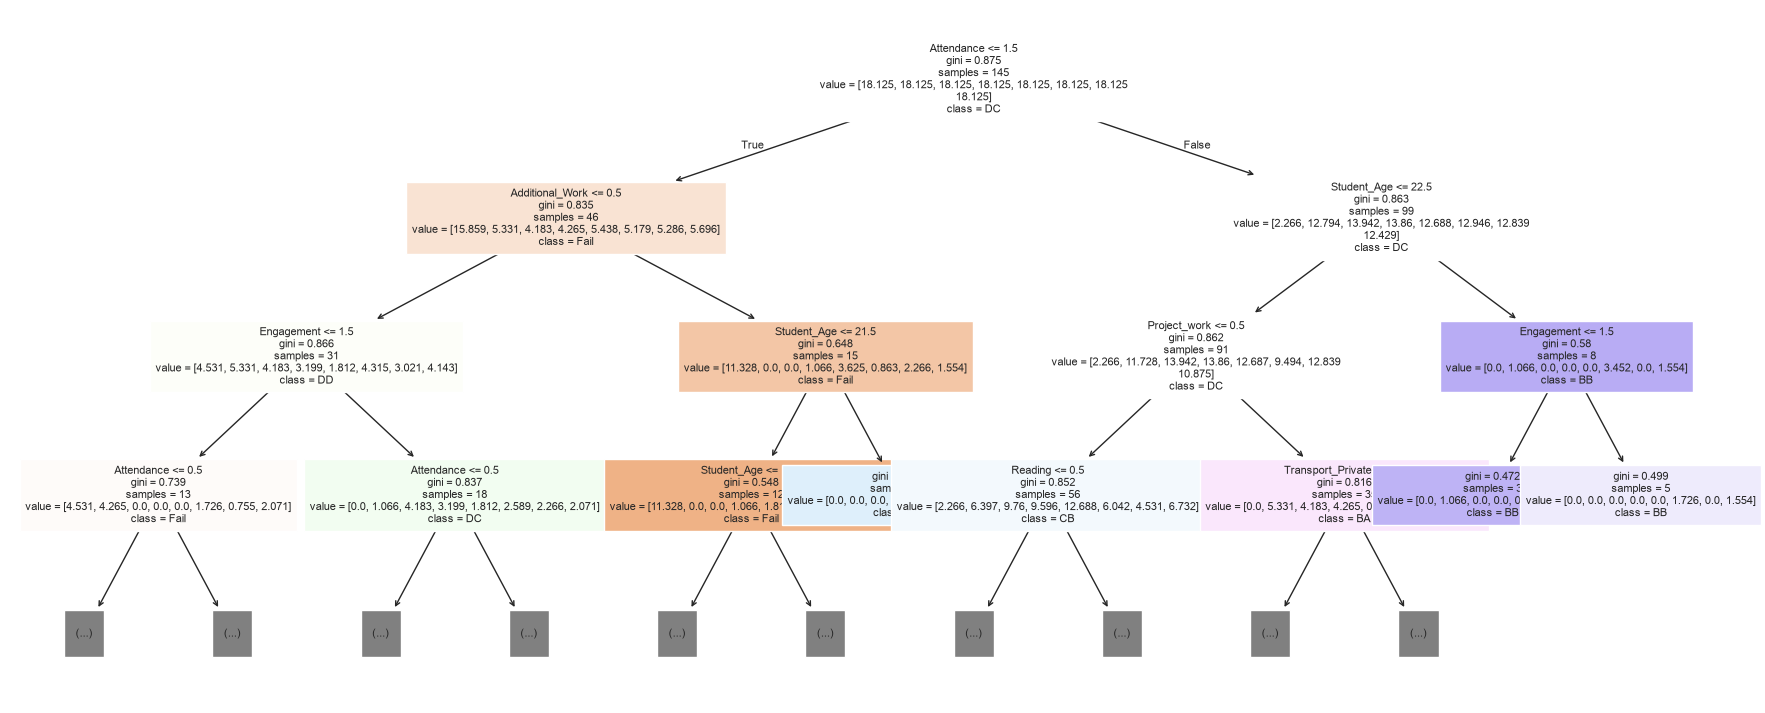

In [40]:
# The tuned decision tree is the readable part of the ensemble
dt = final["Decision tree"].named_steps["model"]
plt.figure(figsize=(22, 9))
plot_tree(dt, feature_names=X.columns, class_names=GRADE_ORDER, filled=True, fontsize=8, max_depth=3)
plt.show()

In [44]:
# Test-set predictions for every student: the grade each model predicted when that student was in the
# held-out fold (first CV repeat, so each student appears exactly once and was never trained on)
test_preds = (oof[oof["repeat"] == 0]
              .pivot(index="idx", columns="model", values="y_pred")[MODEL_ORDER[1:]]
              .apply(lambda s: s.map(dict(enumerate(GRADE_ORDER)))))
test_preds.insert(0, "Id", raw.loc[test_preds.index, "Id"].values)
test_preds.insert(1, "Actual", raw.loc[test_preds.index, "Grade"].values)
test_preds["Ensemble error (grade steps)"] = (
    test_preds["Ensemble (plain average)"].map(GRADE_ORDER.index) - test_preds["Actual"].map(GRADE_ORDER.index))
test_preds = test_preds.sort_values("Id").reset_index(drop=True)

with pd.option_context("display.max_rows", None):
    display(test_preds)

model,Id,Actual,Decision tree,Random forest,CatBoost,XGBoost,LightGBM,Ensemble (plain average),Ensemble error (grade steps)
0,5001,AA,AA,BA,CB,AA,BA,AA,0
1,5002,AA,BA,BA,AA,AA,AA,AA,0
2,5003,AA,DD,DD,DD,DD,DD,DD,-6
3,5004,AA,DD,DD,DD,DD,BA,DD,-6
4,5005,AA,DD,BA,BA,BA,BA,BA,-1
5,5006,BA,BA,BA,BA,BA,BA,BA,0
6,5007,CC,BA,DC,DC,DC,DC,DC,-1
7,5008,BA,Fail,Fail,Fail,CB,AA,Fail,-6
8,5009,CC,AA,DD,DD,DD,DD,DD,-2
9,5010,Fail,BB,BB,BB,BB,BB,BB,5


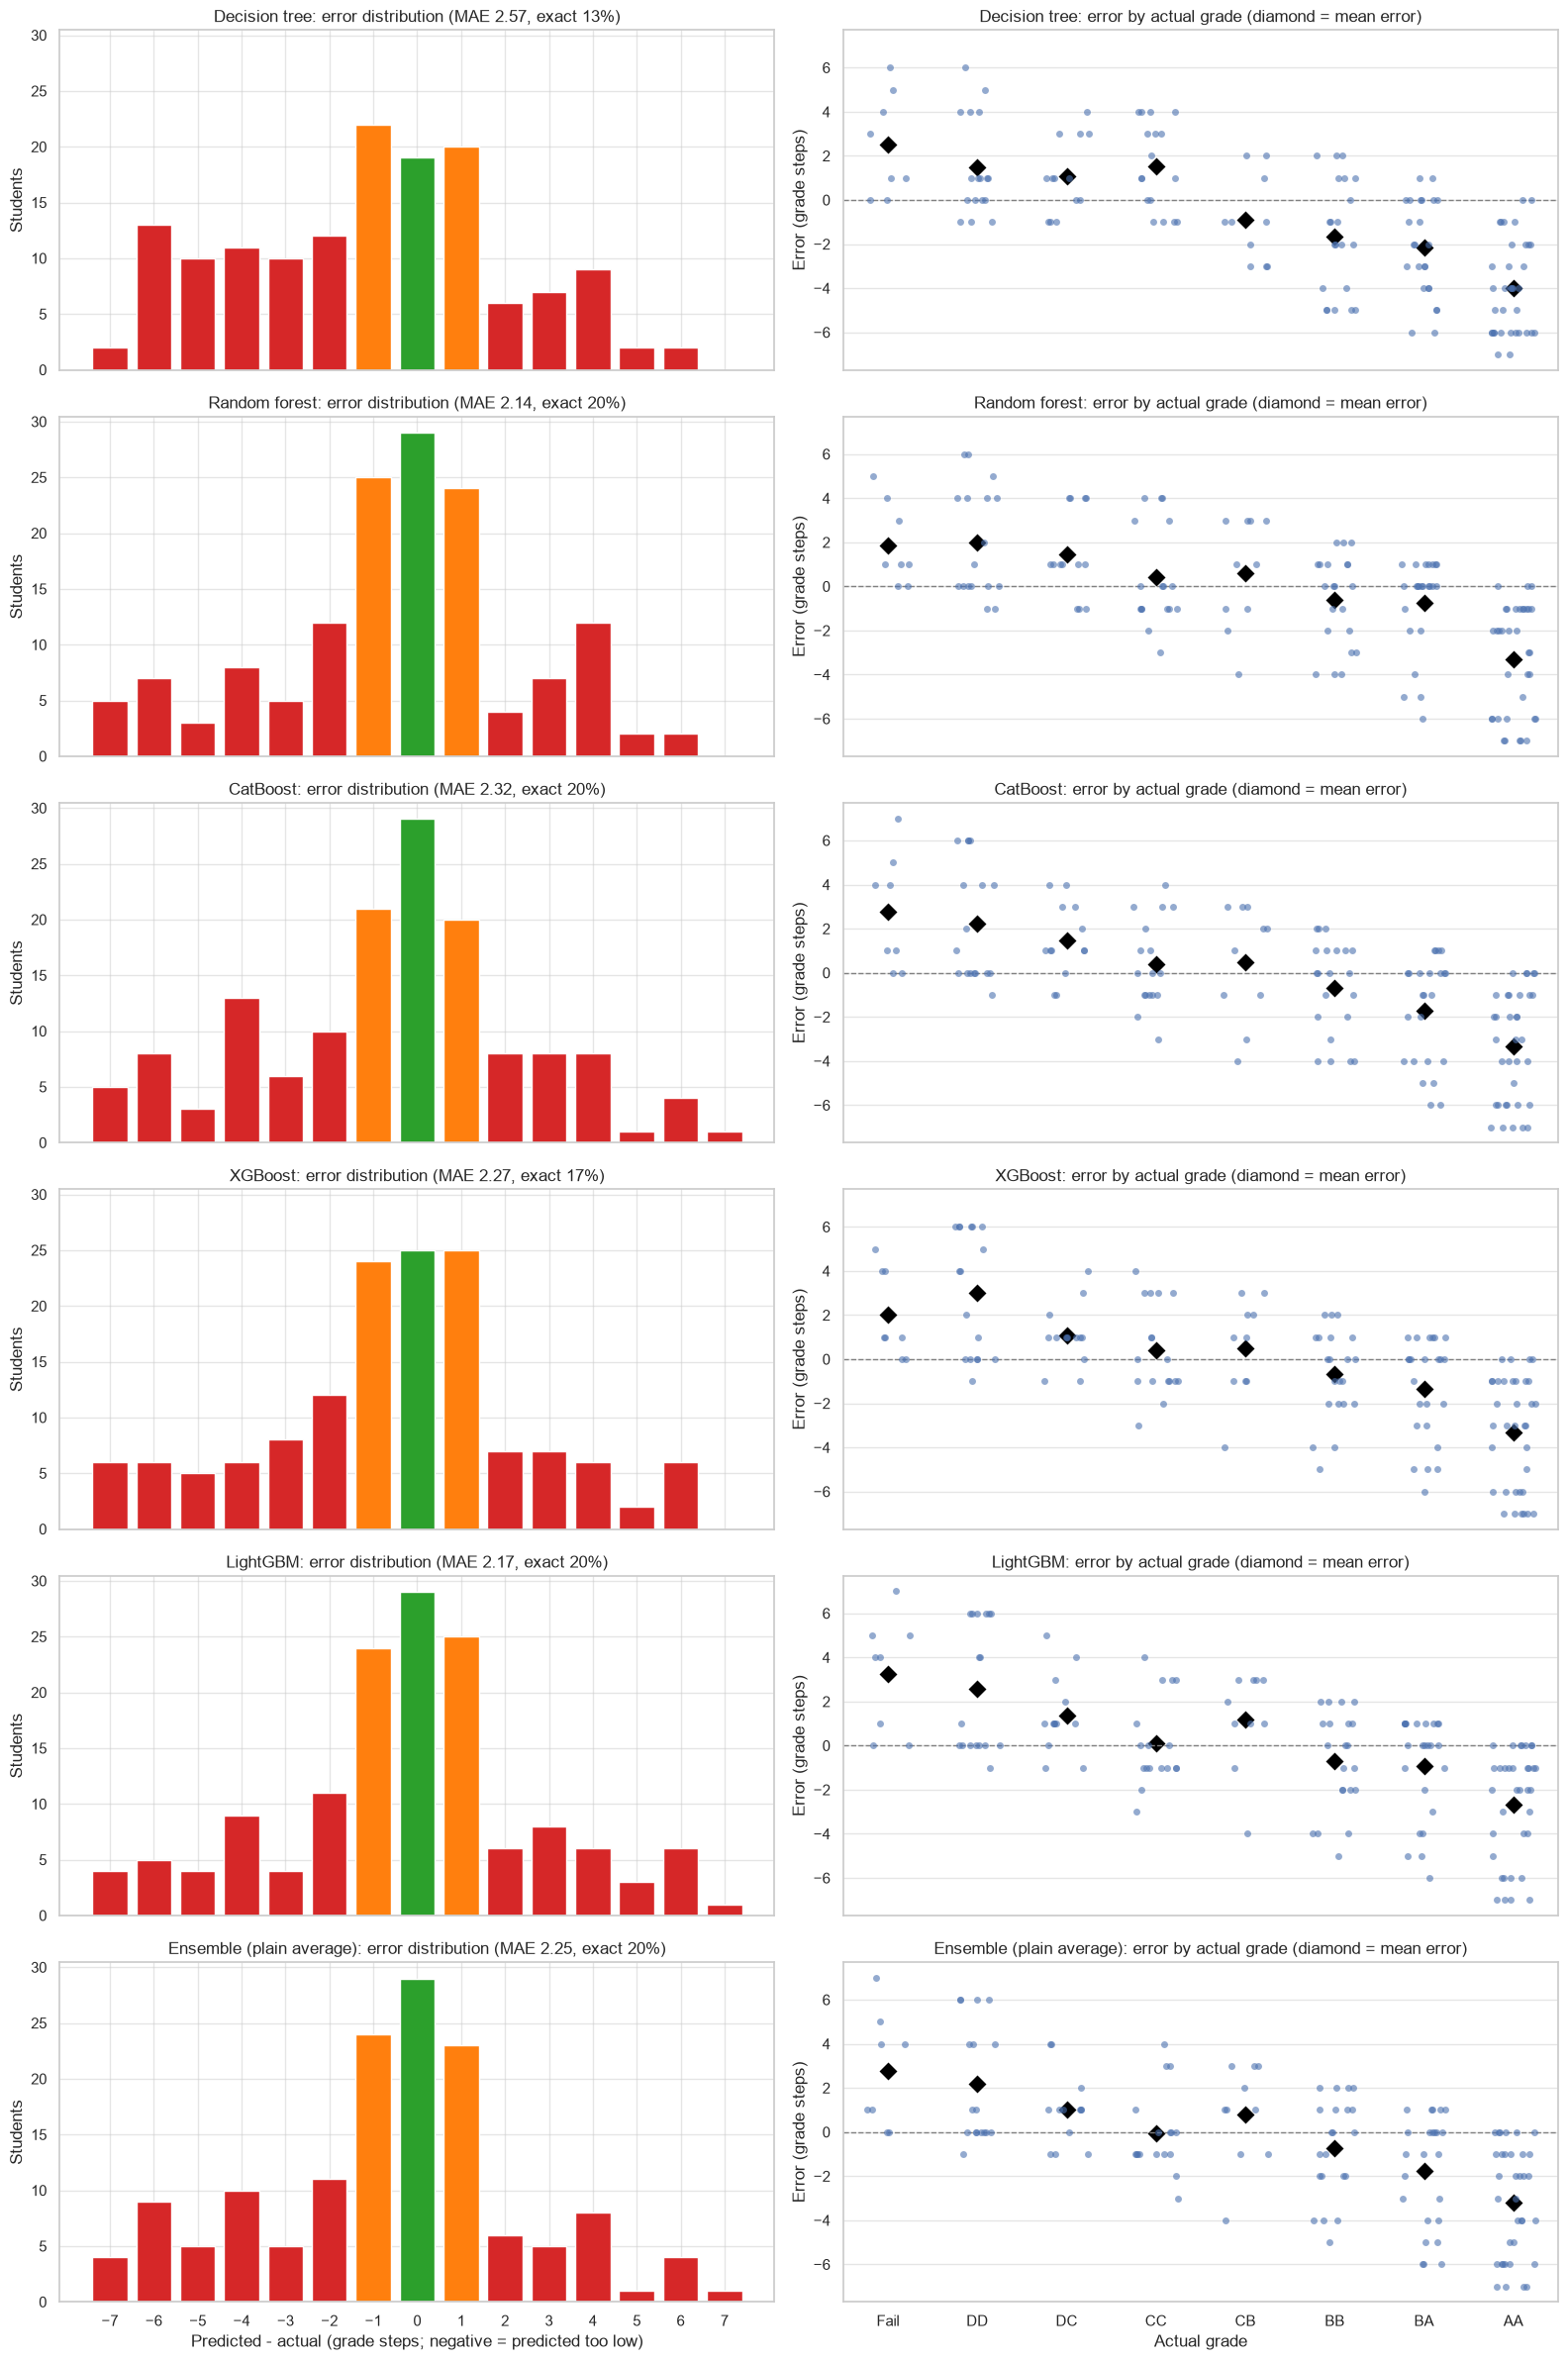

In [45]:
# Test-fold error of every model (ensemble last): overall spread and how it varies by actual grade
plot_models = MODEL_ORDER[1:]   # all models except the baseline
actual_code = test_preds["Actual"].map(GRADE_ORDER.index)
errors = pd.DataFrame({m: test_preds[m].map(GRADE_ORDER.index) - actual_code for m in plot_models})
errors["Actual"] = test_preds["Actual"]

fig, axes = plt.subplots(len(plot_models), 2, figsize=(16, 4 * len(plot_models)), sharex="col", sharey="col")
for row, m in zip(axes, plot_models):
    counts = errors[m].value_counts().reindex(range(-7, 8), fill_value=0)
    colors = ["tab:green" if e == 0 else "tab:orange" if abs(e) == 1 else "tab:red" for e in counts.index]
    row[0].bar(counts.index, counts.values, color=colors)
    row[0].set_xticks(range(-7, 8))
    row[0].set_ylabel("Students")
    row[0].set_title(f"{m}: error distribution (MAE {errors[m].abs().mean():.2f}, exact {(errors[m] == 0).mean():.0%})")

    sns.stripplot(data=errors, x="Actual", y=m, order=GRADE_ORDER, jitter=0.25, alpha=0.6, ax=row[1])
    sns.pointplot(data=errors, x="Actual", y=m, order=GRADE_ORDER, color="black",
                  errorbar=None, markers="D", linestyles="", ax=row[1])
    row[1].axhline(0, color="grey", lw=1, ls="--")
    row[1].set_ylabel("Error (grade steps)")
    row[1].set_title(f"{m}: error by actual grade (diamond = mean error)")

axes[-1, 0].set_xlabel("Predicted - actual (grade steps; negative = predicted too low)")
axes[-1, 1].set_xlabel("Actual grade")
plt.tight_layout(); plt.show()
